# Parte 1 — Análise Exploratória de Dados (EDA)

Objetivo: entender os dados antes de modelar e responder às perguntas da Parte 1 do desafio.
As justificativas de cada decisão estão no [README](../README.md#parte-1--análise-exploratória).

Roteiro: 1. Contexto 
· 2. Divisão treino/teste 
· 3. Formato e tipos 
· 4. Integridade 
· 5. Distribuição de cada variável 
· 6. Relação entre pares de variáveis 
· 7. Efeito de uma terceira variável 
· 8. Registro dos achados

## Passo 1 — Contexto

- Linha: uma campanha (um vídeo veiculado em uma plataforma).
- Alvo: `klike_score` (0 a 100), qualidade geral do criativo segundo a IA da Klike.
- Esperado: 500 registros e 26 colunas.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/klike_challenge_dataset.csv")
df.shape

(500, 26)

## Passo 2 — Divisão treino/teste

Separei o teste antes de explorar, para que nenhuma decisão seja influenciada por ele (evitar *data snooping*).
Daqui em diante, toda a análise usa só o `train`.

- 80% treino (400) / 20% teste (100)
- `random_state=42`: divisão reprodutível
- `stratify=platform`: mesmas proporções de plataforma nos dois conjuntos

In [2]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["platform"])
len(train), len(test)

(400, 100)

In [3]:
proporcoes = pd.DataFrame({
    "base": df["platform"].value_counts(normalize=True),
    "treino": train["platform"].value_counts(normalize=True),
    "teste": test["platform"].value_counts(normalize=True),
})
(proporcoes * 100).round(1)

,base,treino,teste
platform,,,
Meta,48.2,48.2,48.0
TikTok,35.2,35.2,35.0
LinkedIn,16.6,16.5,17.0


Proporções preservadas: a maior diferença em relação à base é de 0,4 ponto percentual (LinkedIn).

## Passo 3 — Formato e tipos

Conferir se cada coluna foi lida com o tipo certo e quais categorias existem. Aqui só observo; as conversões de tipo ficam para o pré-processamento.

In [4]:
exemplos = train.head().T
exemplos.columns = [f"Exemplo {i}" for i in range(1, 6)]
exemplos

,Exemplo 1,Exemplo 2,Exemplo 3,Exemplo 4,Exemplo 5
campaign_id,KLK-0057,KLK-0301,KLK-0088,KLK-0230,KLK-0485
date,2024-02-07,2024-02-10,2024-10-24,2024-05-05,2024-01-05
platform,Meta,Meta,TikTok,TikTok,TikTok
category,E-commerce,Branding,E-commerce,E-commerce,Branding
objective,conversions,awareness,traffic,traffic,engagement
target_audience_age,18-24,35-44,18-24,18-24,18-24
is_retargeting,False,False,False,False,True
video_duration_s,13.0,11.0,11.0,5.0,11.0
format,quadrado,vertical,vertical,vertical,vertical
has_subtitle,True,True,True,False,False


In [5]:
tipos = pd.DataFrame({
    "tipo": train.dtypes.astype(str),
    "preenchidos": train.notna().sum(),
    "faltantes": train.isna().sum(),
    "exemplo": train.apply(lambda col: col.dropna().iloc[0]),
})
tipos

,tipo,preenchidos,faltantes,exemplo
campaign_id,object,400,0,KLK-0057
date,object,400,0,2024-02-07
platform,object,400,0,Meta
category,object,400,0,E-commerce
objective,object,400,0,conversions
target_audience_age,object,400,0,18-24
is_retargeting,bool,400,0,False
video_duration_s,float64,370,30,13.0
format,object,400,0,quadrado
has_subtitle,object,364,36,True


Verificação das categorias contra o dicionário de dados do desafio. Uma categoria nova não é tratada como erro, apenas sinalizada como "fora do dicionário" (ver README, Passo 3).

In [6]:
# Categorias esperadas segundo o dicionário de dados do desafio
CATEGORIAS_ESPERADAS = {
    "platform": ["Meta", "TikTok", "LinkedIn"],
    "category": ["E-commerce", "SaaS", "App Install", "Branding", "Lead Gen"],
    "objective": ["awareness", "traffic", "conversions", "engagement", "app_install"],
    "target_audience_age": ["18-24", "25-34", "35-44", "45+"],
    "format": ["vertical", "horizontal", "quadrado"],
    "text_density": ["low", "medium", "high"],
}


def checar_categorias(col):
    encontradas = set(train[col].dropna().unique())
    esperadas = set(CATEGORIAS_ESPERADAS[col])
    problemas = []
    if encontradas - esperadas:
        problemas.append("fora do dicionário: " + ", ".join(sorted(encontradas - esperadas)))
    if esperadas - encontradas:
        problemas.append("ausentes: " + ", ".join(sorted(esperadas - encontradas)))
    return "; ".join(problemas) or "ok"


pd.DataFrame(
    {"resultado": [checar_categorias(col) for col in CATEGORIAS_ESPERADAS]},
    index=pd.Index(list(CATEGORIAS_ESPERADAS), name="coluna"),
)

,resultado
coluna,
platform,ok
category,ok
objective,ok
target_audience_age,ok
format,ok
text_density,ok


Observações:
- Tipos a corrigir no pré-processamento: `date` (texto → data), `has_subtitle` (`object` por causa de 36 vazios → booleano), `text_density` e `target_audience_age` (categorias com ordem natural, hoje sem ordem).
- Categorias consistentes com o dicionário de dados, sem variações de escrita.
- 7 colunas com valores faltantes (20 a 36 cada), analisadas no Passo 4.

## Passo 4 — Integridade

### 4.1 Valores faltantes

Quantos valores faltam, onde, e se faltam ao acaso ou ligados a outras características da campanha.

In [7]:
colunas_com_faltantes = train.columns[train.isna().any()].tolist()

faltantes = pd.DataFrame({
    "faltantes": train[colunas_com_faltantes].isna().sum(),
    "% do total": train[colunas_com_faltantes].isna().mean() * 100,
})
faltantes.style.format({"% do total": "{:.1f}%"})

,faltantes,% do total
video_duration_s,30,7.5%
has_subtitle,36,9.0%
music_voice_ratio,29,7.2%
cpc,20,5.0%
revenue,22,5.5%
avg_watch_time_s,22,5.5%
engagement_rate,27,6.8%


Entre 5% e 9% de vazios por coluna: pouco o bastante para nenhuma coluna precisar ser descartada.

In [8]:
vazios_por_campanha = train.isna().sum(axis=1).value_counts().sort_index()

tabela_vazios = pd.DataFrame(
    {
        "campanhas": vazios_por_campanha.values,
        "% do total": vazios_por_campanha.values / len(train) * 100,
    },
    index=pd.Index(["nenhum" if n == 0 else str(n) for n in vazios_por_campanha.index],
                   name="campos vazios na campanha"),
)
tabela_vazios.style.format({"% do total": "{:.1f}%"})

,campanhas,% do total
campos vazios na campanha,,
nenhum,250,62.5%
1,118,29.5%
2,28,7.0%
3,4,1.0%


62,5% das campanhas estão completas e quase todas as demais têm um único campo vazio. Os vazios estão espalhados, e não concentrados em poucas campanhas problemáticas.

In [9]:
# % de faltantes de cada coluna dentro de cada plataforma
(train[colunas_com_faltantes].isna().groupby(train["platform"]).mean() * 100).style.format("{:.1f}%")

,video_duration_s,has_subtitle,music_voice_ratio,cpc,revenue,avg_watch_time_s,engagement_rate
platform,,,,,,,
LinkedIn,9.1%,9.1%,12.1%,3.0%,6.1%,1.5%,7.6%
Meta,5.7%,8.3%,6.2%,5.2%,4.7%,5.2%,6.7%
TikTok,9.2%,9.9%,6.4%,5.7%,6.4%,7.8%,6.4%


Taxas parecidas entre plataformas. A maior (`music_voice_ratio` no LinkedIn, 12,1%) corresponde a apenas 8 campanhas.

Teste: para cada coluna com faltantes, comparo as campanhas com e sem o valor vazio nas demais variáveis.
Categóricas: teste qui-quadrado. Numéricas: teste de Mann-Whitney. Como são muitas comparações, os p-valores são corrigidos pelo método de Holm. Listo as diferenças com p < 0,05 antes da correção.

In [10]:
import numpy as np
from scipy.stats import chi2_contingency, mannwhitneyu

VARIAVEIS_CATEGORICAS = ["platform", "category", "objective", "target_audience_age", "format",
                         "text_density", "is_retargeting", "has_hook", "has_face", "has_cta"]
VARIAVEIS_NUMERICAS = ["klike_score", "impressions", "spend", "ctr", "video_duration_s",
                       "engagement_rate", "roas"]


def comparar_com_e_sem_faltante(dados, col):
    vazio = dados[col].isna()
    resultados = []
    for var in VARIAVEIS_CATEGORICAS:
        if var != col:
            p = chi2_contingency(pd.crosstab(dados[var], vazio))[1]
            resultados.append({"variável": var, "p": p, "mediana com vazio": None, "mediana sem vazio": None})
    for var in VARIAVEIS_NUMERICAS:
        if var != col:
            com, sem = dados.loc[vazio, var].dropna(), dados.loc[~vazio, var].dropna()
            resultados.append({"variável": var, "p": mannwhitneyu(com, sem).pvalue,
                               "mediana com vazio": com.median(), "mediana sem vazio": sem.median()})
    return pd.DataFrame(resultados).assign(coluna=col)


def corrigir_holm(p):
    """p-valores ajustados pelo método de Holm para comparações múltiplas."""
    ordem = p.sort_values()
    ajustado = (ordem * (len(ordem) - np.arange(len(ordem)))).cummax().clip(upper=1)
    return ajustado.reindex(p.index)


testes = pd.concat([comparar_com_e_sem_faltante(train, col) for col in colunas_com_faltantes], ignore_index=True)
testes["p corrigido"] = corrigir_holm(testes["p"])
print(f"Total de comparações: {len(testes)}")
testes.loc[testes["p"] < 0.05,
           ["coluna", "variável", "p", "p corrigido", "mediana com vazio", "mediana sem vazio"]].round(3)

Total de comparações: 117


,coluna,variável,p,p corrigido,mediana com vazio,mediana sem vazio
62,cpc,spend,0.048,1.000,2387.335,966.255
63,cpc,ctr,0.042,1.000,0.101,0.063
95,avg_watch_time_s,impressions,0.002,0.267,9045.000,25331.000
96,avg_watch_time_s,spend,0.003,0.391,354.015,1107.300


Das 117 comparações, 4 têm p < 0,05, e nenhuma continua significativa após a correção de Holm: não encontrei evidência contra MCAR. Ainda assim, `avg_watch_time_s` tem os menores p-valores e medianas de impressões e gasto cerca de três vezes menores nas campanhas com vazio. Olho esse caso mais de perto abaixo.

In [11]:
# % de campanhas sem avg_watch_time_s em cada faixa de impressões (5 faixas com 80 campanhas cada)
faixa_impressoes = pd.qcut(train["impressions"], 5,
                           labels=["1 (menores)", "2", "3", "4", "5 (maiores)"])
vazio_watch = train["avg_watch_time_s"].isna()

pd.DataFrame({
    "campanhas sem o valor": vazio_watch.groupby(faixa_impressoes, observed=True).sum(),
    "% da faixa": vazio_watch.groupby(faixa_impressoes, observed=True).mean() * 100,
}).rename_axis("faixa de impressões").style.format({"% da faixa": "{:.1f}%"})

,campanhas sem o valor,% da faixa
faixa de impressões,,
1 (menores),11,13.8%
2,3,3.8%
3,3,3.8%
4,4,5.0%
5 (maiores),1,1.2%


Metade dos vazios de `avg_watch_time_s` (11 de 22) está nos 20% de campanhas com menos impressões. Uma explicação plausível: com poucas visualizações, a plataforma não reporta o tempo médio assistido.

Observações do 4.1:
- Nenhuma diferença sobrevive à correção de Holm: sem evidência contra MCAR nas 7 colunas.
- Exceção provável: `avg_watch_time_s` falta mais em campanhas pequenas (poucas impressões), o que indica MAR. O tratamento precisa levar isso em conta.
- O que fazer com os vazios fica para o pré-processamento (ver README, Passo 4.1).
- `cpc` e `revenue` talvez possam ser recalculados a partir de outras colunas (`spend / clicks` e `roas × spend`); isso é verificado no 4.3.

### 4.2 Duplicatas

Procuro linhas repetidas em quatro níveis, do mais estrito ao mais amplo, e campanhas presentes no treino e no teste ao mesmo tempo. A última checagem só compara se as linhas são iguais; nenhuma estatística do teste é calculada.

In [12]:
CONTEXTO_E_CRIATIVO = ["platform", "category", "objective", "target_audience_age", "is_retargeting",
                       "video_duration_s", "format", "has_subtitle", "has_cta", "has_hook", "has_face",
                       "text_density", "music_voice_ratio"]

sem_id = train.columns.drop("campaign_id")

pd.DataFrame(
    {"linhas": [
        train.duplicated().sum(),
        train["campaign_id"].duplicated().sum(),
        train.duplicated(subset=sem_id).sum(),
        train.duplicated(subset=CONTEXTO_E_CRIATIVO).sum(),
        len(train[sem_id].merge(test[sem_id])),
    ]},
    index=pd.Index([
        "linhas idênticas no treino",
        "campaign_id repetido no treino",
        "linhas idênticas ignorando o campaign_id",
        "mesmo contexto e mesmo vídeo, métricas diferentes",
        "campanhas no treino e no teste ao mesmo tempo",
    ], name="verificação"),
)

,linhas
verificação,
linhas idênticas no treino,0
campaign_id repetido no treino,0
linhas idênticas ignorando o campaign_id,0
"mesmo contexto e mesmo vídeo, métricas diferentes",0
campanhas no treino e no teste ao mesmo tempo,0


Nenhuma duplicata em nenhum nível, e nenhuma sobreposição entre treino e teste: não há linhas a remover.

### 4.3 Valores impossíveis e inconsistentes

Primeiro, regras que valem por definição para qualquer campanha.

In [13]:
pd.DataFrame(
    {"campanhas que violam": [
        (train.select_dtypes("number") < 0).any(axis=1).sum(),
        (train["clicks"] > train["impressions"]).sum(),
        (train["conversions"] > train["clicks"]).sum(),
        (train["avg_watch_time_s"] > train["video_duration_s"]).sum(),
        (~train[["ctr", "engagement_rate", "music_voice_ratio"]].stack().between(0, 1)).sum(),
        (~train["klike_score"].between(0, 100)).sum(),
        (~pd.to_datetime(train["date"]).dt.year.eq(2024)).sum(),
    ]},
    index=pd.Index([
        "algum valor negativo",
        "mais cliques que impressões",
        "mais conversões que cliques",
        "tempo assistido maior que a duração do vídeo",
        "taxa fora de 0 a 1 (ctr, engagement_rate, music_voice_ratio)",
        "klike_score fora de 0 a 100",
        "data fora de 2024",
    ], name="regra"),
)

,campanhas que violam
regra,
algum valor negativo,0
mais cliques que impressões,0
mais conversões que cliques,0
tempo assistido maior que a duração do vídeo,0
"taxa fora de 0 a 1 (ctr, engagement_rate, music_voice_ratio)",0
klike_score fora de 0 a 100,0
data fora de 2024,0


Nenhuma violação.

As métricas derivadas também precisam fechar com as colunas de origem: `ctr = clicks / impressions`, `cpc = spend / clicks` e `roas = revenue / spend`. Meço a diferença relativa entre o valor registrado e o recalculado.

In [14]:
diferencas = pd.DataFrame({
    "ctr": train["ctr"] / (train["clicks"] / train["impressions"]) - 1,
    "cpc": train["cpc"] / (train["spend"] / train["clicks"]) - 1,
    "roas": train["roas"] / (train["revenue"] / train["spend"]) - 1,
}).abs()

faixas = pd.cut(diferencas.stack(), [0, 0.01, 0.1, 0.5, float("inf")], include_lowest=True,
                labels=["até 1%", "1% a 10%", "10% a 50%", "acima de 50%"])
faixas.groupby([faixas.index.get_level_values(1), faixas], observed=False).size().unstack()

,até 1%,1% a 10%,10% a 50%,acima de 50%
cpc,374,0,0,6
ctr,385,11,0,4
roas,302,19,0,2


A distribuição tem um vão: ou a diferença é de até 10% (arredondamento: os cliques são inteiros, então o `ctr` difere sempre menos de 1 clique, e o `roas` tem 2 casas decimais), ou passa de 70%. Nada fica entre os dois. Trato acima de 20% como conta quebrada.

Quando uma conta quebra, uma das duas colunas envolvidas está errada. A regra de correção fica em `src/limpeza.py`, para que a EDA e o pré-processamento usem exatamente a mesma lógica:
- `ctr` não fecha: o erro está em `impressions` ou no próprio `ctr`. Fica o `ctr` mais plausível para a plataforma, e a outra coluna é recalculada.
- `cpc` não fecha: mesmo raciocínio entre `spend` e `cpc`.
- "Mais plausível" = mais perto da mediana da plataforma no treino, em escala log.
- A coluna `coluna_corrigida` registra o que foi alterado.

In [15]:
import sys
sys.path.append("..")
from src.limpeza import corrigir_inconsistencias, medianas_por_plataforma

train_corrigido = corrigir_inconsistencias(train, medianas_por_plataforma(train))
corrigidas = train_corrigido["coluna_corrigida"].notna()

comparacao = pd.DataFrame({
    "campanha": train.loc[corrigidas, "campaign_id"],
    "coluna corrigida": train_corrigido.loc[corrigidas, "coluna_corrigida"],
})
for col in ["impressions", "cpc", "spend"]:
    alterada = comparacao["coluna corrigida"] == col
    comparacao.loc[alterada, "antes"] = train.loc[corrigidas, col][alterada]
    comparacao.loc[alterada, "depois"] = train_corrigido.loc[corrigidas, col][alterada]
comparacao.sort_values("coluna corrigida").set_index("campanha")

,coluna corrigida,antes,depois
campanha,,,
KLK-0240,cpc,24.17,0.98
KLK-0100,cpc,20.00,0.39
KLK-0416,cpc,26.05,0.74
KLK-0232,impressions,12594257.00,11695.00
KLK-0258,impressions,12873562.00,86948.00
KLK-0413,impressions,14052761.00,72059.00
KLK-0148,impressions,13007321.00,42500.00
KLK-0259,spend,95811.69,5.40
KLK-0224,spend,85023.80,21557.40


In [16]:
# o roas não entra na regra, então serve de validação
c = train_corrigido[corrigidas]
fecha = (c["roas"] - c["revenue"] / c["spend"]).abs() < 0.01
print(f"roas fecha em {fecha.sum()} de {len(c)} campanhas corrigidas")

roas fecha em 10 de 10 campanhas corrigidas


10 campanhas (2,5% do treino) têm exatamente uma coluna com erro de registro, e o valor correto pode ser recuperado pelas outras colunas:
- 4 com `impressions` na casa de 13 milhões: o `ctr` e os cliques indicam entre 12 mil e 87 mil.
- 3 com `cpc` entre 20 e 26: `spend / clicks` dá entre 0,39 e 0,98.
- 3 com `spend` inflado: `cpc × clicks` recupera o gasto (ex: KLK-0259, de 95.811 para 5,40).

O `roas` não entra na regra e confirma as correções de `cpc` e `spend`: fecha com o valor escolhido e não fecharia com a alternativa (exceto KLK-0224, sem receita). Nas correções de `impressions`, a alternativa daria CTRs abaixo do mínimo da plataforma.

Receita zero com conversões registradas:

In [17]:
receita_zero = train["revenue"] == 0
pd.DataFrame({
    "campanhas": train.groupby("objective").size(),
    "receita zero": receita_zero.groupby(train["objective"]).sum(),
    "receita zero com conversões": (receita_zero & (train["conversions"] > 0)).groupby(train["objective"]).sum(),
})

,campanhas,receita zero,receita zero com conversões
objective,,,
app_install,37,0,0
awareness,40,22,19
conversions,129,3,0
engagement,66,27,22
traffic,128,3,0


In [18]:
pd.DataFrame({
    "campanhas": train.groupby("category").size(),
    "receita zero": receita_zero.groupby(train["category"]).sum(),
})

,campanhas,receita zero
category,,
App Install,68,0
Branding,49,47
E-commerce,137,1
Lead Gen,73,2
SaaS,73,5


As campanhas com receita zero e conversões são todas de awareness ou engagement, e 47 das 49 campanhas de Branding têm receita zero. Nesses casos, receita zero indica receita não medida, e não performance ruim: o `roas` dessas campanhas não mede retorno.

Vazios de `cpc` e `revenue` (ver 4.1): verifico se as colunas necessárias para recalculá-los estão disponíveis.

In [19]:
pd.DataFrame({
    "vazios": [train["cpc"].isna().sum(), train["revenue"].isna().sum()],
    "recalculáveis": [
        (train["cpc"].isna() & (train["clicks"] > 0) & train["spend"].notna()).sum(),
        (train["revenue"].isna() & train["roas"].notna() & train["spend"].notna()).sum(),
    ],
}, index=pd.Index(["cpc = spend / clicks", "revenue = roas × spend"], name="coluna"))

,vazios,recalculáveis
coluna,,
cpc = spend / clicks,20,20
revenue = roas × spend,22,22


Todos os vazios das duas colunas podem ser recalculados. O `cpc` sai exato; a `revenue`, com o erro de arredondamento do `roas` (2 casas decimais).

Os testes de faltantes do 4.1 usaram os dados com os 10 erros. Repito os testes com os valores corrigidos para checar se a conclusão muda.

In [20]:
testes_corrigidos = pd.concat([comparar_com_e_sem_faltante(train_corrigido, col) for col in colunas_com_faltantes],
                              ignore_index=True)
testes_corrigidos["p corrigido"] = corrigir_holm(testes_corrigidos["p"])
testes_corrigidos.loc[testes_corrigidos["p"] < 0.05,
                      ["coluna", "variável", "p", "p corrigido", "mediana com vazio", "mediana sem vazio"]].round(3)

,coluna,variável,p,p corrigido,mediana com vazio,mediana sem vazio
62,cpc,spend,0.040,1.000,2387.335,930.955
63,cpc,ctr,0.042,1.000,0.101,0.063
95,avg_watch_time_s,impressions,0.003,0.293,9045.000,25056.500
96,avg_watch_time_s,spend,0.004,0.486,354.015,1058.520


Com os valores corrigidos, as mesmas 4 comparações têm p < 0,05 e nenhuma sobrevive à correção de Holm: a conclusão do 4.1 não muda.

Observações do 4.3:
- Nenhuma violação das regras que valem por definição.
- 10 campanhas com erro de registro em uma única coluna (`impressions`, `cpc` ou `spend`), recuperável pelas demais. A correção será aplicada no pré-processamento com `src/limpeza.py`.
- Receita zero em awareness, engagement e Branding indica receita não medida: o `roas` dessas campanhas não mede retorno.
- Os vazios de `cpc` e `revenue` podem ser recalculados em vez de estimados.
- A conclusão sobre os faltantes (4.1) se mantém com os dados corrigidos.

### 4.4 Tetos e pisos

Valores acumulados exatamente no mínimo ou no máximo de uma coluna indicam truncamento: o valor real foi substituído pelo limite. Uso o treino já corrigido no 4.3, para que os erros de registro não se confundam com limites.

In [21]:
colunas_numericas = train_corrigido.select_dtypes("number").columns
pd.DataFrame({
    "mínimo": train_corrigido[colunas_numericas].min(),
    "campanhas no mínimo": train_corrigido[colunas_numericas].eq(train_corrigido[colunas_numericas].min()).sum(),
    "máximo": train_corrigido[colunas_numericas].max(),
    "campanhas no máximo": train_corrigido[colunas_numericas].eq(train_corrigido[colunas_numericas].max()).sum(),
})

,mínimo,campanhas no mínimo,máximo,campanhas no máximo
video_duration_s,5.0000,16,115.00,1
music_voice_ratio,0.0200,1,0.92,1
impressions,1000.0000,2,1570242.00,1
clicks,4.0000,1,72545.00,1
ctr,0.0022,1,0.15,42
cpc,0.1500,1,3.94,1
spend,2.9600,1,84152.20,1
conversions,0.0000,16,3666.00,1
revenue,0.0000,55,241597.29,1
roas,0.0000,59,27.42,1


Acúmulos que chamam atenção: 42 campanhas com `ctr` exatamente 0,15 e 7 com `engagement_rate` exatamente 0,10. Os zeros de `conversions`, `revenue` e `roas` são naturais (ver 4.3). Os pisos de `impressions` (1.000) e `video_duration_s` (5 s) são analisados no fim.

In [22]:
faixas_ctr = pd.cut(train_corrigido["ctr"], [0.09, 0.11, 0.13, 0.1499, 0.15],
                    labels=["0,09 a 0,11", "0,11 a 0,13", "0,13 a 0,15", "exatamente 0,15"])
faixas_ctr.value_counts().sort_index().rename("campanhas").to_frame()

,campanhas
ctr,
"0,09 a 0,11",40
"0,11 a 0,13",26
"0,13 a 0,15",24
"exatamente 0,15",42


In [23]:
no_teto_ctr = train_corrigido["ctr"] == 0.15
(train_corrigido.loc[no_teto_ctr, "clicks"] / train_corrigido.loc[no_teto_ctr, "impressions"]).round(3).value_counts()

0.15    42
Name: count, dtype: int64

O `ctr` tem um teto em 0,15: o pico no limite não segue a tendência das faixas anteriores, e os cliques foram ajustados junto. Para essas 42 campanhas, só se sabe que o CTR real é de pelo menos 15%.

In [24]:
no_teto_eng = train_corrigido["engagement_rate"] == 0.10


def comparar_teto(no_teto):
    resto = ~no_teto
    return {
        "campanhas no teto": no_teto.sum(),
        "plataformas no teto": ", ".join(f"{p} {n}" for p, n in train_corrigido.loc[no_teto, "platform"].value_counts().items()),
        "klike_score mediano (teto)": train_corrigido.loc[no_teto, "klike_score"].median(),
        "klike_score mediano (demais)": train_corrigido.loc[resto, "klike_score"].median(),
        "p (Mann-Whitney)": mannwhitneyu(train_corrigido.loc[no_teto, "klike_score"],
                                         train_corrigido.loc[resto, "klike_score"]).pvalue,
        "% com hook (teto)": train_corrigido.loc[no_teto, "has_hook"].mean() * 100,
        "% com hook (demais)": train_corrigido.loc[resto, "has_hook"].mean() * 100,
    }


pd.DataFrame({
    "ctr = 0,15": comparar_teto(no_teto_ctr),
    "engagement_rate = 0,10": comparar_teto(no_teto_eng),
}).T.style.format({
    "klike_score mediano (teto)": "{:.1f}", "klike_score mediano (demais)": "{:.1f}",
    "p (Mann-Whitney)": "{:.1g}", "% com hook (teto)": "{:.0f}%", "% com hook (demais)": "{:.0f}%",
})

,campanhas no teto,plataformas no teto,klike_score mediano (teto),klike_score mediano (demais),p (Mann-Whitney),% com hook (teto),% com hook (demais)
"ctr = 0,15",42,"Meta 20, TikTok 17, LinkedIn 5",74.4,59.3,2e-07,74%,49%
"engagement_rate = 0,10",7,TikTok 7,57.6,61.2,0.9,43%,52%


O teto do `ctr` não atinge campanhas ao acaso: as campanhas no teto têm `klike_score` bem maior e mais hook. O teto achata justamente as melhores campanhas, então a relação entre CTR e qualidade vai parecer mais fraca do que é.

O teto de `engagement_rate` atinge só o TikTok (7 de 141 campanhas, 5%) e não se associa ao `klike_score`.

In [25]:
piso = train_corrigido["impressions"] == 1000
train_corrigido.loc[piso, ["campaign_id", "platform", "impressions", "clicks", "ctr"]].assign(
    **{"impressões indicadas pelo ctr": (train_corrigido.loc[piso, "clicks"] / train_corrigido.loc[piso, "ctr"]).round()})

,campaign_id,platform,impressions,clicks,ctr,impressões indicadas pelo ctr
371,KLK-0372,Meta,1000,89,0.0899,990.0
40,KLK-0041,Meta,1000,23,0.0234,983.0


In [26]:
pd.crosstab(train_corrigido["video_duration_s"], train_corrigido["platform"]).loc[5:10]

platform,LinkedIn,Meta,TikTok
video_duration_s,,,
5.0,0,5,11
6.0,0,3,7
7.0,0,7,7
8.0,0,6,6
9.0,0,7,13
10.0,2,7,6


Os dois pisos têm efeito pequeno:
- `impressions`: 2 campanhas em exatamente 1.000, com valor original de 983 e 990 (menos de 2% de diferença).
- `video_duration_s`: leve acúmulo em 5 s (16 campanhas, contra 10 em 6 s), quase todas do TikTok. Pode ser um piso, mas a evidência é fraca.

Observações do 4.4:
- `ctr` truncado em 0,15 em 42 campanhas (10,5%), que têm `klike_score` e uso de hook bem acima das demais. Pré-processamento: manter o valor e adicionar a coluna indicadora `ctr_no_teto`.
- `engagement_rate` truncado em 0,10 em 7 campanhas do TikTok, sem associação com o `klike_score`. Pré-processamento: manter o valor e adicionar `engagement_no_teto`.
- Recomendações do engine não podem projetar CTR acima de 15%, fora do que os dados mostram.
- Pisos de `impressions` (1.000) e `video_duration_s` (5 s): apenas registrados, efeito desprezível.

## Passo 5 — Distribuição de cada variável

Daqui em diante, uso o treino com os erros de registro corrigidos (4.3).

In [27]:
import matplotlib.pyplot as plt
from pathlib import Path

PASTA_FIGURAS = Path("../figures")
PASTA_FIGURAS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COR = "#3b6ea5"

dados = train_corrigido

### 5.1 Alvo: `klike_score`

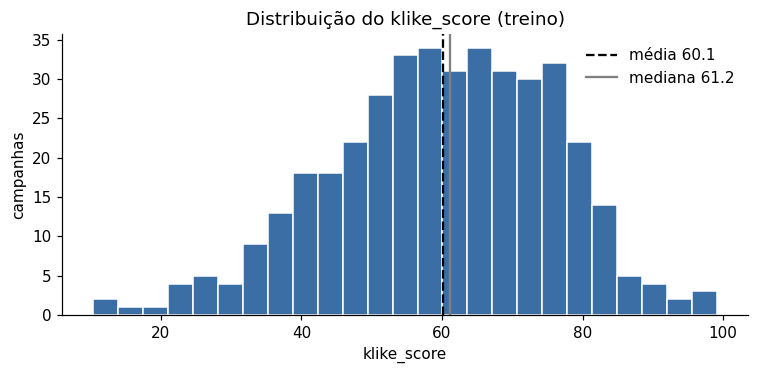

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(dados["klike_score"], bins=25, color=COR, edgecolor="white")
ax.axvline(dados["klike_score"].mean(), color="black", linestyle="--", label=f"média {dados['klike_score'].mean():.1f}")
ax.axvline(dados["klike_score"].median(), color="gray", label=f"mediana {dados['klike_score'].median():.1f}")
ax.set(xlabel="klike_score", ylabel="campanhas", title="Distribuição do klike_score (treino)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "01_klike_score.png")

Distribuição próxima de simétrica, centrada em 60 (média 60,1, mediana 61,2), cobrindo quase toda a escala (10 a 99). Não há acúmulo nos extremos, e metade das campanhas fica entre 50 e 72. O alvo não precisa de transformação.

### 5.2 Variáveis numéricas

In [29]:
numericas = ["video_duration_s", "music_voice_ratio", "impressions", "clicks", "ctr", "cpc", "spend",
             "conversions", "revenue", "roas", "avg_watch_time_s", "engagement_rate"]
resumo = pd.DataFrame({
    "média": dados[numericas].mean(),
    "mediana": dados[numericas].median(),
    "média / mediana": dados[numericas].mean() / dados[numericas].median(),
    "assimetria": dados[numericas].skew(),
    "assimetria em log": np.log1p(dados[numericas]).skew(),
})
resumo.style.format({"média": "{:,.3f}", "mediana": "{:,.3f}", "média / mediana": "{:.1f}",
                     "assimetria": "{:.1f}", "assimetria em log": "{:.1f}"})

,média,mediana,média / mediana,assimetria,assimetria em log
video_duration_s,19.738,16.000,1.2,2.6,0.3
music_voice_ratio,0.398,0.390,1.0,0.2,-0.1
impressions,"50,263.445","23,486.500",2.1,9.6,0.0
clicks,"3,644.972","1,364.500",2.7,5.3,-0.2
ctr,0.071,0.064,1.1,0.4,0.4
cpc,0.960,0.705,1.4,2.0,1.4
spend,"3,400.485","1,027.980",3.3,5.5,-0.1
conversions,136.382,35.000,3.9,6.1,-0.0
revenue,"6,296.122","1,224.270",5.1,8.9,-1.0
roas,2.463,1.590,1.5,3.1,0.5


As contagens e valores monetários (`impressions`, `clicks`, `spend`, `conversions`, `revenue`) têm cauda longa: a média é de 2 a 5 vezes a mediana, e a assimetria cai para perto de zero em escala log. Por isso os histogramas abaixo usam escala log nessas colunas.

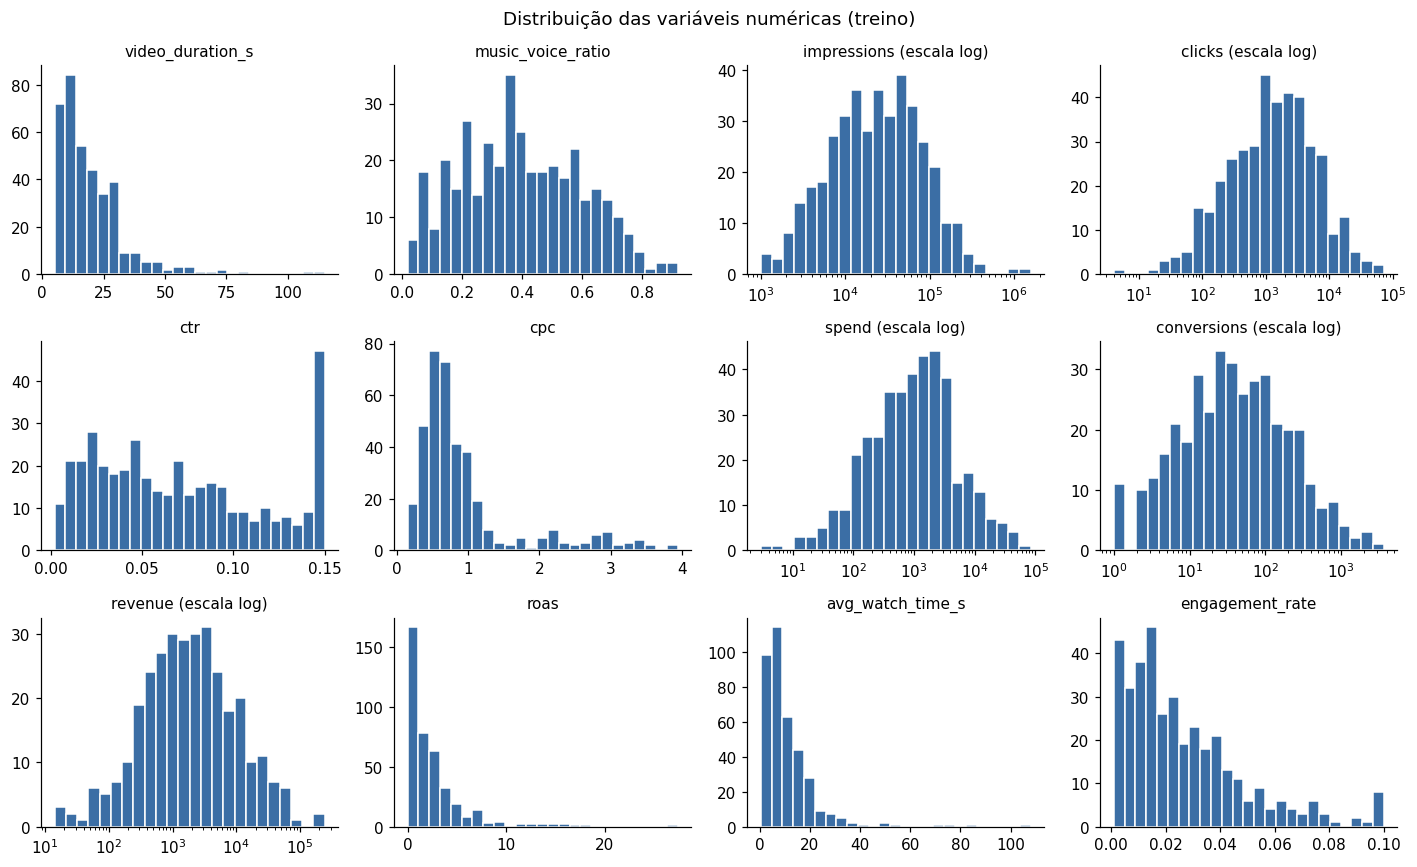

In [30]:
CAUDA_LONGA = ["impressions", "clicks", "spend", "conversions", "revenue"]

fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, col in zip(axes.flat, numericas):
    valores = dados[col].dropna()
    if col in CAUDA_LONGA:
        valores = valores[valores > 0]
        bins = np.logspace(np.log10(valores.min()), np.log10(valores.max()), 25)
        ax.set_xscale("log")
        ax.set_title(f"{col} (escala log)", fontsize=10)
    else:
        bins = 25
        ax.set_title(col, fontsize=10)
    ax.hist(valores, bins=bins, color=COR, edgecolor="white")
fig.suptitle("Distribuição das variáveis numéricas (treino)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "02_numericas.png")

- Em escala log, as contagens e valores monetários ficam próximos de simétricos: o comportamento é multiplicativo, típico de mídia paga.
- `revenue` e `conversions` mostram os zeros do 4.3 (campanhas sem receita medida), que ficam fora do gráfico em log.
- `ctr` e `engagement_rate` mostram os tetos do 4.4 como uma barra isolada no limite.
- `video_duration_s` concentra a maioria dos vídeos entre 5 e 30 s, com poucos acima de 60 s.
- `roas` e `avg_watch_time_s` também têm cauda à direita, mais moderada.
- `cpc` tem um segundo grupo entre 2 e 4: é o LinkedIn, cuja mediana (2,38) é cerca de três vezes a do Meta (0,80) e quatro vezes a do TikTok (0,51).
- `music_voice_ratio` é a única próxima de simétrica, sem cauda.

### 5.3 Variáveis categóricas

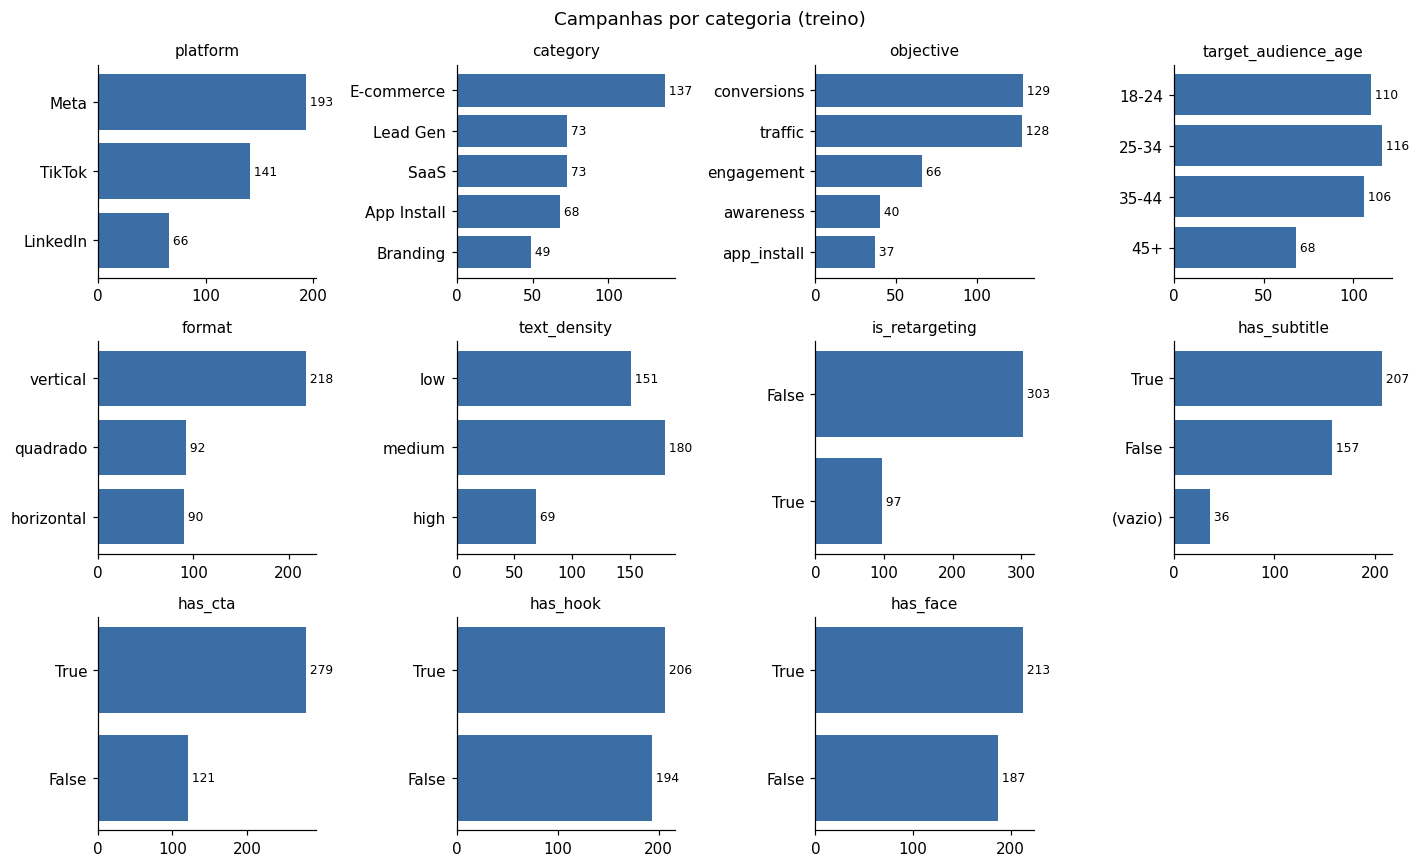

In [31]:
categoricas = ["platform", "category", "objective", "target_audience_age", "format", "text_density",
               "is_retargeting", "has_subtitle", "has_cta", "has_hook", "has_face"]
ORDEM = {"target_audience_age": ["18-24", "25-34", "35-44", "45+"],
         "text_density": ["low", "medium", "high"]}

fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, col in zip(axes.flat, categoricas):
    contagem = dados[col].astype("string").fillna("(vazio)").value_counts()
    if col in ORDEM:
        contagem = contagem.reindex(ORDEM[col])
    ax.barh(contagem.index[::-1], contagem.values[::-1], color=COR)
    ax.set_title(col, fontsize=10)
    for i, v in enumerate(contagem.values[::-1]):
        ax.text(v, i, f" {v}", va="center", fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Campanhas por categoria (treino)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "03_categoricas.png")

- Nenhuma categoria rara: a menor é `app_install` em `objective` (37 campanhas, 9%).
- Meta concentra quase metade das campanhas, e LinkedIn só 66: análises por plataforma no LinkedIn terão menos precisão.
- Formato vertical predomina (55%). Os atributos binários do criativo são equilibrados, exceto `is_retargeting` (24% sim) e `has_cta` (70% sim).

Duas combinações chamam atenção e serão analisadas no passo 6:

In [32]:
pd.crosstab(dados["category"], dados["objective"])

objective,app_install,awareness,conversions,engagement,traffic
category,,,,,
App Install,37,0,0,0,31
Branding,0,23,0,26,0
E-commerce,0,0,67,0,70
Lead Gen,0,0,33,40,0
SaaS,0,17,29,0,27


In [33]:
pd.crosstab(dados["platform"], dados["format"])

format,horizontal,quadrado,vertical
platform,,,
LinkedIn,35,22,9
Meta,55,51,87
TikTok,0,19,122


- Cada categoria usa só dois objetivos (ex: Branding aparece apenas com awareness e engagement), e o objetivo `app_install` só existe na categoria App Install. As duas colunas são parcialmente redundantes.
- TikTok não tem nenhum vídeo horizontal, e LinkedIn quase nenhum vertical: o efeito do formato vai se misturar com o da plataforma.

Observações do passo 5:
- `klike_score` aproximadamente simétrico, sem transformação necessária.
- Contagens e valores monetários com cauda longa: candidatos a transformação log no pré-processamento.
- Categorias sem níveis raros; LinkedIn é a plataforma com menos dados.
- `category` × `objective` e `platform` × `format` são combinações estruturadas, a investigar no passo 6.

## Passo 6 — Relação entre pares de variáveis

Atributos do criativo × `klike_score` e × métricas de performance. Volumes (impressões, cliques, gasto) dependem do orçamento, então comparo taxas:
- `ctr` e `engagement_rate`;
- `watch_ratio` = `avg_watch_time_s / video_duration_s`: fração média do vídeo assistida;
- `conversion_rate` = `conversions / clicks`;
- `roas`, só onde a receita é medida (4.3).

In [34]:
analise = dados.assign(
    has_subtitle=dados["has_subtitle"].astype("boolean"),
    watch_ratio=dados["avg_watch_time_s"] / dados["video_duration_s"],
    conversion_rate=dados["conversions"] / dados["clicks"],
    roas=dados["roas"].mask((dados["roas"] == 0) & (dados["conversions"] > 0)),
)

### 6.1 Atributos do criativo × `klike_score` e métricas

In [35]:
# rótulo: (coluna, valor comparado, valor de referência)
COMPARACOES = {
    "hook": ("has_hook", True, False),
    "rosto humano": ("has_face", True, False),
    "call-to-action": ("has_cta", True, False),
    "legenda": ("has_subtitle", True, False),
    "texto médio (vs alto)": ("text_density", "medium", "high"),
    "texto baixo (vs alto)": ("text_density", "low", "high"),
    "retargeting (contexto)": ("is_retargeting", True, False),
}
METRICAS = ["klike_score", "ctr", "engagement_rate", "watch_ratio", "conversion_rate", "roas"]


def comparar(base, coluna, valor, referencia, metrica):
    a = base.loc[base[coluna] == valor, metrica].dropna()
    b = base.loc[base[coluna] == referencia, metrica].dropna()
    diferenca = a.median() - b.median()
    if metrica != "klike_score":
        diferenca = diferenca / b.median() * 100
    return {"diferença": diferenca, "p": mannwhitneyu(a, b).pvalue, "n com": len(a), "n sem": len(b)}


efeitos = pd.DataFrame([
    {"atributo": rotulo, "métrica": metrica, **comparar(analise, *args, metrica)}
    for rotulo, args in COMPARACOES.items() for metrica in METRICAS
])
efeitos["p corrigido"] = corrigir_holm(efeitos["p"])
efeitos["significativo"] = efeitos["p corrigido"] < 0.05

Diferença na mediana do `klike_score` (em pontos), com intervalo de confiança de 95% por bootstrap:

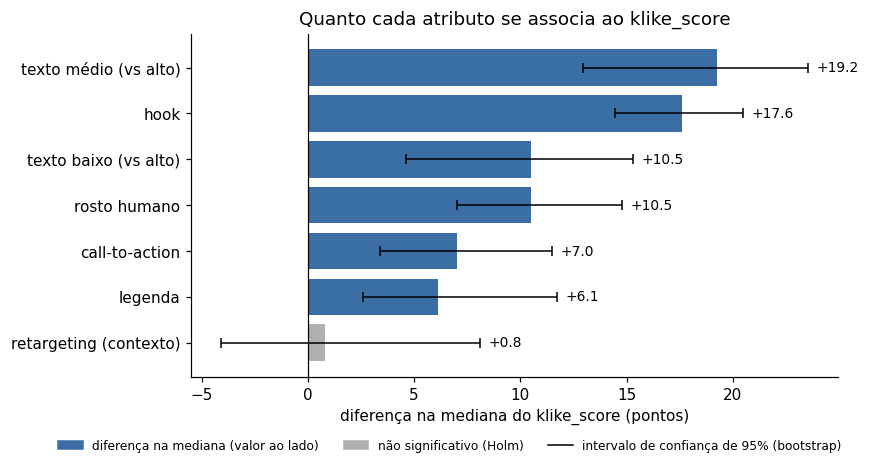

In [36]:
def intervalo_bootstrap(base, coluna, valor, referencia, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    a = base.loc[base[coluna] == valor, "klike_score"].to_numpy()
    b = base.loc[base[coluna] == referencia, "klike_score"].to_numpy()
    difs = [np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(n)]
    return np.percentile(difs, [2.5, 97.5])


score = efeitos[efeitos["métrica"] == "klike_score"].set_index("atributo")
score[["ic inferior", "ic superior"]] = [intervalo_bootstrap(analise, *COMPARACOES[a]) for a in score.index]
score = score.sort_values("diferença")

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(8, 4.4))
cores = [COR if s else "#b0b0b0" for s in score["significativo"]]
ax.barh(score.index, score["diferença"], color=cores)
ax.errorbar(score["diferença"], score.index,
            xerr=[score["diferença"] - score["ic inferior"], score["ic superior"] - score["diferença"]],
            fmt="none", ecolor="black", capsize=3, linewidth=1)
for i, (v, superior) in enumerate(zip(score["diferença"], score["ic superior"])):
    ax.text(superior + 0.4, i, f"{v:+.1f}", va="center", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="diferença na mediana do klike_score (pontos)",
       title="Quanto cada atributo se associa ao klike_score")
ax.legend(handles=[
    Patch(color=COR, label="diferença na mediana (valor ao lado)"),
    Patch(color="#b0b0b0", label="não significativo (Holm)"),
    Line2D([], [], color="black", linewidth=1, label="intervalo de confiança de 95% (bootstrap)"),
], loc="upper center", bbox_to_anchor=(0.4, -0.15), ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "04_atributos_klike_score.png")

In [37]:
score[["diferença", "ic inferior", "ic superior", "p corrigido", "n com", "n sem"]].iloc[::-1].style.format(
    {"diferença": "{:+.1f}", "ic inferior": "{:+.1f}", "ic superior": "{:+.1f}", "p corrigido": "{:.1g}"})

,diferença,ic inferior,ic superior,p corrigido,n com,n sem
atributo,,,,,,
texto médio (vs alto),+19.2,+13.0,+23.6,3e-11,180,69
hook,+17.6,+14.4,+20.5,7e-27,206,194
texto baixo (vs alto),+10.5,+4.6,+15.3,0.0005,151,69
rosto humano,+10.5,+7.0,+14.8,2e-10,213,187
call-to-action,+7.0,+3.4,+11.5,0.0002,279,121
legenda,+6.1,+2.6,+11.7,0.0006,207,157
retargeting (contexto),+0.8,-4.1,+8.1,1,97,303


Todos os atributos do criativo se associam ao `klike_score` após a correção de Holm. Os maiores efeitos são a densidade de texto (média fica 19 pontos acima de alta) e o hook (+17,6). Retargeting, uma decisão de mídia e não do criativo, não se associa ao score.

Variação relativa da mediana de cada métrica de performance (%):

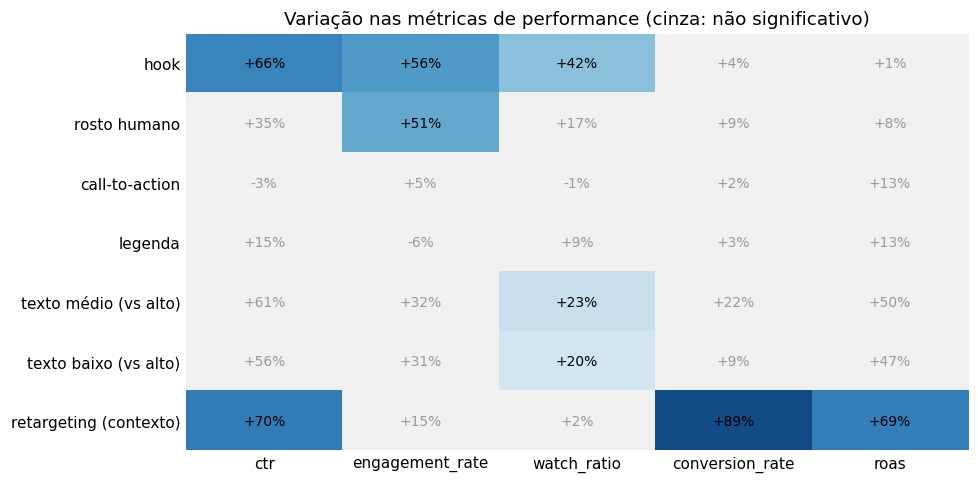

In [38]:
desempenho = efeitos[efeitos["métrica"] != "klike_score"]
valores = desempenho.pivot(index="atributo", columns="métrica", values="diferença").loc[list(COMPARACOES), METRICAS[1:]]
significativo = desempenho.pivot(index="atributo", columns="métrica", values="significativo").loc[valores.index, valores.columns]

fig, ax = plt.subplots(figsize=(9, 4.5))
mapa = plt.get_cmap("RdBu").copy()
mapa.set_bad("#f0f0f0")
ax.imshow(valores.where(significativo).clip(-100, 100), cmap=mapa, vmin=-100, vmax=100, aspect="auto")
for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        ax.text(j, i, f"{valores.iat[i, j]:+.0f}%", ha="center", va="center", fontsize=9,
                color="black" if significativo.iat[i, j] else "#9a9a9a")
ax.set_xticks(range(valores.shape[1]), valores.columns)
ax.set_yticks(range(valores.shape[0]), valores.index)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Variação nas métricas de performance (cinza: não significativo)")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "05_atributos_metricas.png")

Cinza: não significativo após a correção de Holm (42 comparações nesta seção).
- Hook e rosto humano agem nas métricas de atenção: hook aumenta CTR (+66%), engajamento (+56%) e retenção (+42%); rosto aumenta o engajamento (+51%).
- Texto médio ou baixo aumenta a retenção em relação a texto alto (+20% a +23%).
- Nenhum atributo do criativo altera significativamente conversão ou ROAS. Essas métricas dependem da audiência: retargeting aumenta a conversão em 89% e o ROAS em 69%, mas não muda o `klike_score`.
- CTA e legenda elevam o `klike_score` sem efeito detectável nas métricas.
- Efeitos com p < 0,05 apenas antes da correção (ex: rosto no CTR, +35%; texto médio no CTR, +61%) ficam como hipóteses.

### 6.2 Duração do vídeo e proporção música/voz

In [39]:
from scipy.stats import spearmanr

pd.DataFrame({
    (atributo, metrica): dict(zip(["correlação", "p"], spearmanr(analise[atributo], analise[metrica], nan_policy="omit")))
    for atributo in ["video_duration_s", "music_voice_ratio"]
    for metrica in ["klike_score", "ctr", "watch_ratio", "engagement_rate"]
}).T.style.format({"correlação": "{:+.2f}", "p": "{:.2g}"})

In [40]:
faixas_duracao = pd.cut(analise["video_duration_s"], [0, 10, 15, 20, 30, 45, 200],
                        labels=["até 10 s", "11-15 s", "16-20 s", "21-30 s", "31-45 s", "acima de 45 s"])
analise.groupby(faixas_duracao, observed=True)[["klike_score", "ctr", "watch_ratio", "engagement_rate"]].median().assign(
    campanhas=faixas_duracao.value_counts()).round(3)

,klike_score,ctr,watch_ratio,engagement_rate,campanhas
video_duration_s,,,,,
até 10 s,61.20,0.061,0.480,0.026,87
11-15 s,61.20,0.071,0.504,0.021,96
16-20 s,59.10,0.063,0.562,0.024,53
21-30 s,61.70,0.070,0.557,0.020,87
31-45 s,57.45,0.047,0.524,0.018,28
acima de 45 s,61.20,0.052,0.436,0.015,19


Nem a duração nem a proporção música/voz se relacionam com o `klike_score`, o CTR ou a retenção. A duração tem associação fraca e negativa com o engajamento (−0,15), e vídeos acima de 45 s têm a menor retenção, mas são só 19 campanhas.

### 6.3 Métricas de performance × `klike_score`

In [41]:
metricas_desempenho = ["impressions", "clicks", "spend", "conversions", "revenue", "ctr", "cpc", "roas",
                       "avg_watch_time_s", "watch_ratio", "engagement_rate", "conversion_rate"]
analise[metricas_desempenho].corrwith(analise["klike_score"], method="spearman").sort_values(ascending=False).rename(
    "correlação de Spearman com klike_score").to_frame().style.format("{:+.2f}")

,correlação de Spearman com klike_score
ctr,+0.56
watch_ratio,+0.42
revenue,+0.35
conversions,+0.34
roas,+0.32
clicks,+0.30
engagement_rate,+0.28
spend,+0.24
avg_watch_time_s,+0.23
conversion_rate,+0.19


O `klike_score` acompanha principalmente o CTR (+0,56) e a retenção (+0,42). Volumes como impressões e gasto quase não se relacionam com ele. A retenção relativa (`watch_ratio`) se relaciona mais com o score que o tempo assistido absoluto (+0,42 contra +0,23).

In [42]:
# pares de métricas muito correlacionados (redundantes)
correlacoes = analise[metricas_desempenho + ["video_duration_s"]].corr(method="spearman")
pares = correlacoes.where(np.triu(np.ones(correlacoes.shape, dtype=bool), k=1)).stack()
pares[pares.abs() > 0.7].sort_values(ascending=False).rename("correlação").to_frame().style.format("{:+.2f}")

Os volumes (impressões, cliques, gasto, conversões, receita) são muito correlacionados entre si: medem basicamente o tamanho da campanha. `avg_watch_time_s` é dominado pela duração do vídeo (+0,76), o que justifica usar a razão `watch_ratio`.

### 6.4 Atributos do criativo entre si

In [43]:
analise[["has_hook", "has_face", "has_cta", "has_subtitle", "is_retargeting"]].astype(float).corr().style.format("{:+.2f}")

,has_hook,has_face,has_cta,has_subtitle,is_retargeting
has_hook,+1.00,+0.02,-0.01,-0.11,-0.06
has_face,+0.02,+1.00,+0.00,-0.00,-0.01
has_cta,-0.01,+0.00,+1.00,+0.01,+0.02
has_subtitle,-0.11,-0.00,+0.01,+1.00,-0.02
is_retargeting,-0.06,-0.01,+0.02,-0.02,+1.00


Os atributos do criativo são praticamente independentes entre si (|r| ≤ 0,11): o efeito de um não é reflexo de outro.

Observações do passo 6:
- Atributos com maior associação ao `klike_score`: densidade de texto (alta é a pior), hook, rosto, CTA e legenda, nessa ordem.
- Hook e rosto melhoram as métricas de atenção (CTR, engajamento, retenção); nenhum atributo do criativo muda conversão ou ROAS, que dependem da audiência (retargeting).
- O `klike_score` avalia o criativo, não a audiência: retargeting melhora as métricas, mas não o score.
- Duração e proporção música/voz não têm relação com o score.
- Volumes são redundantes entre si; `watch_ratio` e `conversion_rate` são boas candidatas a feature.

## Passo 7 — Efeito de uma terceira variável

As relações do passo 6 se mantêm dentro de cada plataforma? E as diferenças entre plataformas vêm da plataforma em si ou da composição das campanhas de cada uma?

### 7.1 Efeito dos atributos no `klike_score`, por plataforma

In [44]:
PLATAFORMAS = ["Meta", "TikTok", "LinkedIn"]
ATRIBUTOS_CRIATIVO = [a for a in COMPARACOES if a != "retargeting (contexto)"]

por_plataforma = pd.DataFrame([
    {"atributo": rotulo, "plataforma": plataforma, "métrica": metrica,
     **comparar(analise[analise["platform"] == plataforma], *COMPARACOES[rotulo], metrica)}
    for rotulo in ATRIBUTOS_CRIATIVO for plataforma in PLATAFORMAS
    for metrica in ["klike_score", "ctr", "engagement_rate"]
])
por_plataforma["p corrigido"] = corrigir_holm(por_plataforma["p"])
por_plataforma["significativo"] = por_plataforma["p corrigido"] < 0.05

score_plataforma = por_plataforma[por_plataforma["métrica"] == "klike_score"]
score_plataforma.pivot(index="atributo", columns="plataforma", values="diferença").loc[ATRIBUTOS_CRIATIVO, PLATAFORMAS].style.format("{:+.1f}")

plataforma,Meta,TikTok,LinkedIn
atributo,,,
hook,+18.3,+17.0,+17.3
rosto humano,+12.2,+8.8,+11.8
call-to-action,+7.5,+4.7,+10.3
legenda,+6.9,+5.1,+10.9
texto médio (vs alto),+19.2,+17.0,+17.9
texto baixo (vs alto),+9.2,+12.0,+9.9


Os efeitos no `klike_score` são praticamente iguais nas três plataformas: hook vale de 17 a 18 pontos, texto médio em vez de alto de 17 a 19, e rosto de 9 a 12 em todas.

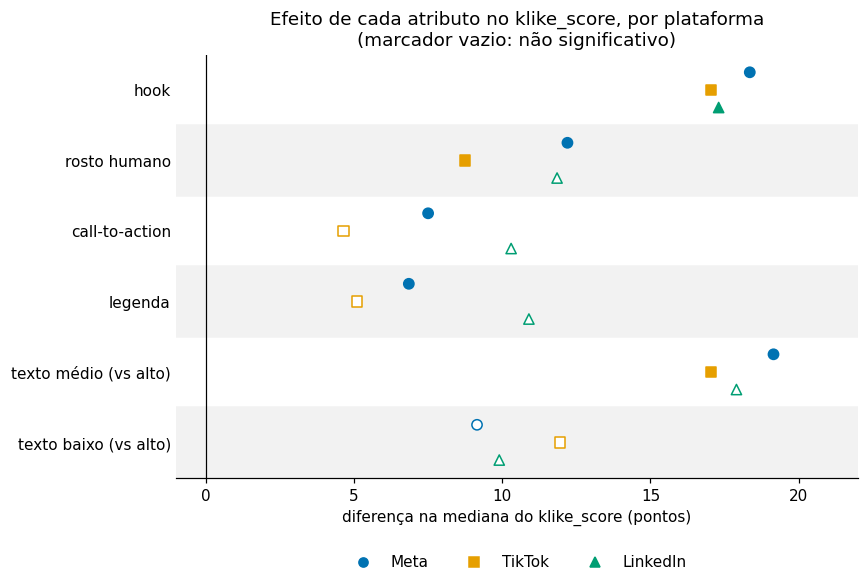

In [45]:
from matplotlib.lines import Line2D

CORES_PLATAFORMA = {"Meta": "#0072B2", "TikTok": "#E69F00", "LinkedIn": "#009E73"}
MARCADORES = {"Meta": "o", "TikTok": "s", "LinkedIn": "^"}

fig, ax = plt.subplots(figsize=(8, 5.5))
for k, plataforma in enumerate(PLATAFORMAS):
    linhas = score_plataforma[score_plataforma["plataforma"] == plataforma].set_index("atributo").loc[ATRIBUTOS_CRIATIVO[::-1]]
    y = np.arange(len(linhas)) - (k - 1) * 0.25  # Meta em cima, LinkedIn embaixo
    cor = CORES_PLATAFORMA[plataforma]
    ax.scatter(linhas["diferença"], y, marker=MARCADORES[plataforma], s=45, edgecolors=cor,
               facecolors=[cor if s else "white" for s in linhas["significativo"]])
ax.set_yticks(range(len(ATRIBUTOS_CRIATIVO)), ATRIBUTOS_CRIATIVO[::-1])
for i in range(0, len(ATRIBUTOS_CRIATIVO), 2):  # faixas alternadas separam os atributos
    ax.axhspan(i - 0.5, i + 0.5, color="#f2f2f2", zorder=0)
ax.set_ylim(-0.5, len(ATRIBUTOS_CRIATIVO) - 0.5)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)  # a linha do zero já serve de referência
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 22)
ax.set(xlabel="diferença na mediana do klike_score (pontos)",
       title="Efeito de cada atributo no klike_score, por plataforma\n(marcador vazio: não significativo)")
ax.legend(handles=[Line2D([], [], marker=MARCADORES[p], color=CORES_PLATAFORMA[p], linestyle="", label=p)
                   for p in PLATAFORMAS], frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "06_atributos_por_plataforma.png")

No LinkedIn só o hook é significativo após a correção, porque a plataforma tem poucas campanhas (66); os tamanhos de efeito, porém, são da mesma ordem dos outros. O padrão observado no geral vale em cada plataforma.

### 7.2 Efeito nas métricas de atenção, por plataforma

In [46]:
def tabela_metrica(metrica):
    linhas = por_plataforma[por_plataforma["métrica"] == metrica]
    texto = linhas["diferença"].map("{:+.0f}%".format) + np.where(linhas["significativo"], " *", "")
    return linhas.assign(texto=texto).pivot(index="atributo", columns="plataforma", values="texto").loc[
        ATRIBUTOS_CRIATIVO, PLATAFORMAS]


tabela_metrica("ctr").rename_axis(columns="variação no ctr")

variação no ctr,Meta,TikTok,LinkedIn
atributo,,,
hook,+53%,+83% *,+133%
rosto humano,+3%,+66%,+64%
call-to-action,-2%,-9%,+26%
legenda,+28%,+6%,-15%
texto médio (vs alto),+67%,+49%,+33%
texto baixo (vs alto),+45%,+61%,+22%


In [47]:
tabela_metrica("engagement_rate").rename_axis(columns="variação no engagement_rate")

variação no engagement_rate,Meta,TikTok,LinkedIn
atributo,,,
hook,+43% *,+29%,+12%
rosto humano,+50% *,+33%,+23%
call-to-action,+16%,-11%,-18%
legenda,-22%,-20%,+58%
texto médio (vs alto),+38%,+16%,+23%
texto baixo (vs alto),+10%,+58%,+21%


`*`: significativo após a correção de Holm (63 comparações nesta seção).

Nas métricas, os efeitos variam mais entre plataformas, mas poucas diferenças sobrevivem à correção com amostras menores:
- Hook aumenta o CTR nas três plataformas (+53% a +133%), significativo no TikTok.
- Rosto aumenta o CTR no TikTok e no LinkedIn (+66% e +64%), mas não no Meta (+3%); no Meta, o ganho do rosto aparece no engajamento (+50%, significativo).
- Esses padrões são indicativos, não confirmados: ficam como hipóteses para o engine.

### 7.3 Formato do vídeo dentro de cada plataforma

In [48]:
formato = analise.pivot_table(index="format", columns="platform", values="klike_score", aggfunc=["median", "size"])
formato.columns = [f"{'mediana' if f == 'median' else 'campanhas'} {p}" for f, p in formato.columns]
formato[[f"{t} {p}" for p in PLATAFORMAS for t in ["mediana", "campanhas"]]].round(1)

,mediana Meta,campanhas Meta,mediana TikTok,campanhas TikTok,mediana LinkedIn,campanhas LinkedIn
format,,,,,,
horizontal,58.0,55.0,NaN,NaN,58.2,35.0
quadrado,64.3,51.0,61.2,19.0,50.0,22.0
vertical,61.7,87.0,62.4,122.0,42.6,9.0


In [49]:
from scipy.stats import kruskal

print("p (Kruskal-Wallis) do formato:", {p: round(float(kruskal(*[g["klike_score"] for _, g in analise[analise["platform"] == p].groupby("format")]).pvalue), 3)
                                         for p in PLATAFORMAS})
linkedin = analise[analise["platform"] == "LinkedIn"]
(linkedin.groupby("format")[["has_hook", "has_face"]].mean() * 100).round(0).rename(columns=lambda c: f"% {c}")

p (Kruskal-Wallis) do formato: {'Meta': 0.187, 'TikTok': 0.191, 'LinkedIn': 0.013}


,% has_hook,% has_face
format,,
horizontal,54.0,54.0
quadrado,55.0,64.0
vertical,22.0,33.0


Formato não tem efeito no Meta nem no TikTok (Kruskal-Wallis, p ≈ 0,19 em ambos). No LinkedIn, vídeos verticais têm score bem menor (42,6 contra 58,2 dos horizontais), mas são só 9 campanhas, e só 22% delas têm hook (contra 54% das horizontais) e 33% têm rosto (contra 54%). A diferença é explicada principalmente pela composição desses vídeos, e não pelo formato.

### 7.4 Duração e proporção música/voz, por plataforma

In [50]:
duracao_musica = pd.DataFrame([
    {"atributo": atributo, "plataforma": plataforma, "métrica": metrica,
     **dict(zip(["correlação", "p"], spearmanr(grupo[atributo], grupo[metrica], nan_policy="omit")))}
    for atributo in ["video_duration_s", "music_voice_ratio"]
    for plataforma, grupo in analise.groupby("platform")
    for metrica in ["klike_score", "ctr", "watch_ratio", "engagement_rate"]
])
duracao_musica["p corrigido"] = corrigir_holm(duracao_musica["p"])
duracao_musica.pivot(index=["atributo", "plataforma"], columns="métrica", values="correlação")[
    ["klike_score", "ctr", "watch_ratio", "engagement_rate"]].style.format("{:+.2f}")

In [51]:
duracao_musica.nsmallest(3, "p").round(3)

,atributo,plataforma,métrica,correlação,p,p corrigido
18,music_voice_ratio,Meta,watch_ratio,0.207,0.008,0.192
23,music_voice_ratio,TikTok,engagement_rate,0.138,0.127,1.000
20,music_voice_ratio,TikTok,klike_score,-0.131,0.136,1.000


In [52]:
faixas_plataforma = pd.cut(analise["video_duration_s"], [0, 15, 30, 200], labels=["até 15 s", "16-30 s", "acima de 30 s"])
analise.groupby(["platform", faixas_plataforma], observed=True).agg(
    klike_score=("klike_score", "median"), ctr=("ctr", "median"), watch_ratio=("watch_ratio", "median"),
    campanhas=("klike_score", "size")).loc[PLATAFORMAS].round(3)

klike_score    ctr  watch_ratio  campanhas
platform video_duration_s                                            
Meta     até 15 s                63.70  0.076        0.538         83
         16-30 s                 59.10  0.063        0.539         73
         acima de 30 s           62.45  0.047        0.538         26
TikTok   até 15 s                61.00  0.056        0.473         88
         16-30 s                 65.80  0.088        0.562         35
         acima de 30 s           66.80  0.027        0.402          5
LinkedIn até 15 s                48.60  0.074        0.420         12
         16-30 s                 55.75  0.057        0.583         32
         acima de 30 s           56.55  0.052        0.534         16

Nenhuma das 24 correlações é significativa após a correção de Holm. O sinal mais forte, música/voz × retenção no Meta (+0,21), é fraco e não se repete nas outras plataformas. No TikTok, vídeos acima de 30 s têm CTR mediano menor (2,7% contra 5,6% dos vídeos até 15 s), mas são só 5 campanhas. Não há base nos dados para uma duração ideal por plataforma.

### 7.5 Rosto humano e faixa etária

In [53]:
rosto_idade = analise.pivot_table(index="target_audience_age", columns="has_face", values="engagement_rate", aggfunc="median")
rosto_idade.columns = ["sem rosto", "com rosto"]
rosto_idade["variação"] = rosto_idade["com rosto"] / rosto_idade["sem rosto"] - 1
rosto_idade["campanhas"] = analise.groupby("target_audience_age").size()
rosto_idade.style.format({"sem rosto": "{:.4f}", "com rosto": "{:.4f}", "variação": "{:+.0%}"})

,sem rosto,com rosto,variação,campanhas
target_audience_age,,,,
18-24,0.0212,0.0340,+61%,110
25-34,0.0174,0.0252,+45%,116
35-44,0.0132,0.0207,+57%,106
45+,0.0213,0.0245,+15%,68


Rosto aumenta o engajamento em todas as faixas etárias, com efeito menor no público 45+ (+15%, contra +45% a +61% nas demais).

### 7.6 Diferenças entre plataformas

In [54]:
pd.DataFrame({
    "campanhas": analise.groupby("platform").size(),
    "klike_score mediano": analise.groupby("platform")["klike_score"].median(),
    "% com hook": analise.groupby("platform")["has_hook"].mean() * 100,
    "% texto alto": analise["text_density"].eq("high").groupby(analise["platform"]).mean() * 100,
    "% público 35+": analise["target_audience_age"].isin(["35-44", "45+"]).groupby(analise["platform"]).mean() * 100,
    "cpc mediano": analise.groupby("platform")["cpc"].median(),
    "ctr mediano": analise.groupby("platform")["ctr"].median(),
}).loc[PLATAFORMAS].round(2)

,campanhas,klike_score mediano,% com hook,% texto alto,% público 35+,cpc mediano,ctr mediano
platform,,,,,,,
Meta,193,61.4,55.44,12.95,49.74,0.79,0.07
TikTok,141,62.3,46.81,19.86,23.40,0.51,0.06
LinkedIn,66,55.5,50.00,24.24,68.18,2.38,0.06


In [55]:
# klike_score mediano por plataforma, dentro de grupos com o mesmo hook e a mesma densidade de texto
analise.pivot_table(index=["has_hook", "text_density"], columns="platform", values="klike_score", aggfunc="median")[PLATAFORMAS].round(1)

platform               Meta  TikTok  LinkedIn
has_hook text_density                        
False    high          43.1    42.0      24.2
         low           51.8    53.8      48.8
         medium        57.8    59.4      50.8
True     high          55.9    54.4      52.4
         low           67.1    72.0      65.6
         medium        76.5    74.9      72.5

In [56]:
# diferença média do LinkedIn para as outras plataformas, comparando grupos com o mesmo hook, rosto e densidade de texto
grupos = ["has_hook", "has_face", "text_density"]
medias = analise.groupby(grupos + ["platform"])["klike_score"].mean().unstack()
peso = linkedin.groupby(grupos).size()
{outra: round(float(((medias["LinkedIn"] - medias[outra]) * peso).sum() / peso[medias[outra].notna()].sum()), 1)
 for outra in ["Meta", "TikTok"]}

{'Meta': -3.8, 'TikTok': -4.8}

O LinkedIn tem score mediano 6 a 7 pontos abaixo das outras plataformas. Parte disso é composição: o LinkedIn tem mais campanhas com texto alto (24%, contra 13% no Meta). Comparando campanhas com o mesmo hook, rosto e densidade de texto, a diferença cai, mas não some: o LinkedIn fica cerca de 4 a 5 pontos abaixo dentro dos mesmos grupos. O LinkedIn também tem CPC cerca de três vezes maior e público mais velho (68% com 35 anos ou mais).

### 7.7 Efeito dos atributos por categoria do anunciante

O efeito de cada atributo muda entre E-commerce, Lead Gen, SaaS, App Install e Branding? Mesma comparação do 7.1, agora por categoria.

In [57]:
CATEGORIAS = ["E-commerce", "Lead Gen", "SaaS", "App Install", "Branding"]

por_categoria = pd.DataFrame([
    {"atributo": rotulo, "categoria": categoria, "métrica": metrica,
     **comparar(analise[analise["category"] == categoria], *COMPARACOES[rotulo], metrica)}
    for rotulo in ATRIBUTOS_CRIATIVO for categoria in CATEGORIAS
    for metrica in ["klike_score", "ctr", "engagement_rate"]
])
por_categoria["p corrigido"] = corrigir_holm(por_categoria["p"])
por_categoria["significativo"] = por_categoria["p corrigido"] < 0.05

score_categoria = por_categoria[por_categoria["métrica"] == "klike_score"]
texto = score_categoria["diferença"].map("{:+.1f}".format) + np.where(score_categoria["significativo"], " *", "")
score_categoria.assign(texto=texto).pivot(index="atributo", columns="categoria", values="texto").loc[
    ATRIBUTOS_CRIATIVO, CATEGORIAS].rename_axis(columns="variação no klike_score (pontos)")

variação no klike_score (pontos),E-commerce,Lead Gen,SaaS,App Install,Branding
atributo,,,,,
hook,+11.5 *,+22.9 *,+20.7 *,+19.2 *,+18.1 *
rosto humano,+5.4,+7.8,+17.2 *,+15.5 *,+13.5
call-to-action,+1.5,+6.6,+18.0,+10.9,+5.9
legenda,+7.6 *,+6.6,+10.5,+0.7,+3.2
texto médio (vs alto),+15.2 *,+24.5,+23.9 *,+15.0,+20.9
texto baixo (vs alto),+9.5,+11.8,+10.9,+5.4,+13.0


In [58]:
print("campanhas por categoria:", analise["category"].value_counts()[CATEGORIAS].to_dict())
print("efeitos significativos após a correção (90 comparações):",
      por_categoria.groupby("métrica")["significativo"].sum().to_dict())

campanhas por categoria: {'E-commerce': 137, 'Lead Gen': 73, 'SaaS': 73, 'App Install': 68, 'Branding': 49}
efeitos significativos após a correção (90 comparações): {'ctr': 0, 'engagement_rate': 0, 'klike_score': 10}


Todos os efeitos no score são positivos nas cinco categorias, e o hook é significativo em todas. Os tamanhos variam mais que entre plataformas (ex: hook de +11,5 no E-commerce a +22,9 no Lead Gen), mas os grupos são pequenos (49 a 137 campanhas) e as diferenças são brutas. Nas métricas, nenhuma das 60 comparações por categoria é significativa após a correção. Se as variações forem reais, interações atributo × categoria devem melhorar o modelo; o notebook 02 (seção 4.1) testa isso, e elas não melhoram.

Observações do passo 7:
- O que funciona no TikTok funciona no LinkedIn: o efeito dos atributos do criativo no `klike_score` é o mesmo nas três plataformas.
- As métricas de atenção respondem de forma diferente por plataforma (ex: rosto aumenta o CTR no TikTok e no LinkedIn, e o engajamento no Meta), mas com evidência mais fraca.
- O formato só parece importar no LinkedIn, e a diferença é explicada pela composição (vídeos verticais com menos hook e rosto).
- Duração e proporção música/voz continuam sem efeito dentro de cada plataforma.
- A categoria do anunciante também não muda o efeito dos atributos: as variações entre categorias não melhoram o modelo.
- O LinkedIn tem score base cerca de 4 a 5 pontos menor, mesmo comparando campanhas parecidas.

## Passo 8 — Registro dos achados

### Fatos sobre os dados
- 400 campanhas no treino (Meta 48%, TikTok 35%, LinkedIn 17%), todas de 2024.
- `klike_score` aproximadamente simétrico (10 a 99, mediana 61).
- Atributos associados ao score, em ordem de efeito: densidade de texto (alta é a pior, média a melhor), hook, rosto, CTA e legenda. Os efeitos são os mesmos nas três plataformas.
- Duração, proporção música/voz, formato, categoria e objetivo não se associam ao score.
- O score acompanha o CTR e a retenção, mas não a audiência: retargeting melhora conversão e ROAS sem mudar o score.
- O LinkedIn tem score base cerca de 4 a 5 pontos menor, mesmo comparando campanhas parecidas.

### Problemas a corrigir no pré-processamento
1. Tipos: `has_subtitle` para booleano (e `date` para data, se a data entrar no modelo).
2. 10 erros de registro: `corrigir_inconsistencias` (`src/limpeza.py`), com medianas do treino.
3. Faltantes: `cpc` = `spend / clicks` e `revenue` = `roas × spend`; demais colunas com a mediana do treino e coluna indicadora (`avg_watch_time_s` provavelmente MAR).
4. Receita não medida (`roas` = 0 com conversões): tratar como "não se aplica", e não como zero.
5. Tetos: indicadoras `ctr_no_teto` e `engagement_no_teto`.
6. Variáveis com cauda longa: transformação log.
7. Categorias novas: codificação que aceite categorias não vistas no treino.

### Hipóteses a testar com modelos
1. Atributos do criativo e contexto explicam boa parte do score, com efeitos aproximadamente aditivos: uma regressão linear deve ir bem, e interações por plataforma devem ajudar pouco.
2. O efeito de `text_density` não segue a ordem dos níveis (média > baixa > alta): codificar como categórica, e não como ordinal.
3. Métricas de atenção (`ctr`, `watch_ratio`) devem aumentar o poder preditivo, mas só existem depois da veiculação.
4. Duração, música/voz, formato, categoria e objetivo devem ter importância baixa.